# Домашнее задание 1 — Message passing своими руками
Федоров Александр
**Группа:** 

## Чек-лист выполненных пунктов

- [x] Часть 1 — реализация `MyGCNConv` и `MySAGEConv` в `submission.py`, все 7 автотестов проходят
- [x] Часть 2 — воспроизведение результата Kipf & Welling (2017) на Cora и CiteSeer, 5 сидов, mean±std, MLP baseline
- [x] Часть 3 — эксперимент с глубиной 2/4/8/16, accuracy + косинусное сходство представлений, объяснение over-smoothing
- [x] Бонус A — inductive vs transductive на GraphSAGE, 5 сидов на режим
- [x] Бонус B — зависимость accuracy от доли разметки (1/5/20/60%), GCN vs MLP

## Окружение

- `torch==2.14.1+cu126`
- `torch-geometric==2.8.1`
- `numpy==2.4.6`
- `matplotlib==3.11.2`
- `pytest==9.2.0`




In [1]:
import sys
from pathlib import Path

working_dir = Path.cwd().resolve()
homework_candidates = [working_dir, working_dir / "my_works" / "HW"]
HOMEWORK_DIR = next((p for p in homework_candidates if (p / "submission.py").is_file()), None)
if HOMEWORK_DIR is None:
    raise FileNotFoundError("Open the notebook from its folder or the course repository root.")
if str(HOMEWORK_DIR) not in sys.path:
    sys.path.insert(0, str(HOMEWORK_DIR))
TEST_PATH = next(
    (p / "tasks" / "tests" / "test_task1.py" for p in [HOMEWORK_DIR, *HOMEWORK_DIR.parents]
     if (p / "tasks" / "tests" / "test_task1.py").is_file()),
    None,
)
if TEST_PATH is None:
    raise FileNotFoundError("Could not find tasks/tests/test_task1.py in the course repository.")
COURSE_DIR = TEST_PATH.parents[2]

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q torch_geometric pytest matplotlib


In [2]:
import copy
import random
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import Tensor
from torch_geometric.data import Data
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import subgraph, to_undirected

from submission import MyGCNConv, MySAGEConv


def set_seed(seed: int) -> None:
    """Фиксирует все источники случайности для воспроизводимости."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"torch {torch.__version__}")

SEEDS = [0, 1, 2, 3, 4]
N_LAYERS_DEPTH = [2, 4, 8, 16]
LABEL_FRACIONS = [0.01, 0.05, 0.20, 0.60]
HIDDEN_DIM = 64
DROPOUT_RATE = 0.5
LEARNING_RATE = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300

device: cuda
GPU: NVIDIA GeForce RTX 3090
torch 2.14.1+cu126


c:\Users\Alexander\PycharmProjects\gnn-course-itmo\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Часть 1 — реализация слоёв и автотесты

Оба слоя реализованы в `submission.py` через `torch_geometric.utils.scatter`. Кратко:

- **`MyGCNConv`**: добавляем self-петли, считаем степени с петлями, взвешиваем каждое сообщение как $1/\sqrt{d_v \cdot d_u}$ (где $d$ — степени с петлями), собираем сумму по целевой вершине (вторая строка `edge_index`).
- **`MySAGEConv`**: среднее по соседям (без петель) через отдельную матрицу `lin_neigh`, собственный вектор — через отдельную матрицу `lin_self`, выход = сумма двух.

> Тонкость контракта: эталонные `GCNConv(..., bias=False)` и `SAGEConv(..., bias=False)` в автотестах копируют **только веса**, поэтому мои слои по умолчанию создаются без bias (`bias=False`). Для обучения моделей ниже я явно передаю `bias=True` — это ровно поведение слоёв PyG.

Запуск автотестов (вывод сохранён из реального прогона):

In [3]:
import os
import subprocess

test_env = os.environ.copy()
test_env["PYTHONPATH"] = os.pathsep.join(filter(None, [str(HOMEWORK_DIR), test_env.get("PYTHONPATH", "")]))
test_run = subprocess.run(
    [sys.executable, "-m", "pytest", str(TEST_PATH), "-v"],
    cwd=HOMEWORK_DIR, env=test_env, capture_output=True, text=True,
)
print(test_run.stdout)
if test_run.stderr:
    print(test_run.stderr)
assert test_run.returncode == 0 and "7 passed" in test_run.stdout, "Tests failed or were skipped"


============================= test session starts =============================
platform win32 -- Python 3.11.0, pytest-9.2.0, pluggy-1.7.0 -- c:\Users\Alexander\PycharmProjects\gnn-course-itmo\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Alexander\PycharmProjects\gnn-course-itmo
configfile: pyproject.toml
plugins: anyio-4.16.0, platformdirs-4.14.5
collecting ... collected 7 items

..\..\tasks\tests\test_task1.py::test_gcn_output_shape PASSED            [ 14%]
..\..\tasks\tests\test_task1.py::test_gcn_matches_pyg PASSED             [ 28%]
..\..\tasks\tests\test_task1.py::test_gcn_on_directed_graph PASSED       [ 42%]
..\..\tasks\tests\test_task1.py::test_gcn_permutation_invariance PASSED  [ 57%]
..\..\tasks\tests\test_task1.py::test_gcn_isolated_node_is_finite PASSED [ 71%]
..\..\tasks\tests\test_task1.py::test_sage_matches_pyg PASSED            [ 85%]
..\..\tasks\tests\test_task1.py::test_gcn_is_trainable PASSED            [100%]

============================== 7

In [4]:
# Test output is produced by the preceding cell.


## Модели и цикл обучения

Общий каркас: `GCNNet` и `SAGENet` — стеки из моих слоёв с ReLU и dropout; `MLPNet` — тот же размер без графа. Гиперпараметры фиксированы (lr=0.01, wd=5e-4, 300 эпох, hidden=64, dropout=0.5) и **одинаковы для всех моделей и всех частей задания** — ничего не подбирается по тестовой выборке.

In [5]:
class GCNNet(torch.nn.Module):
    """Стек MyGCNConv: скрытые слои с ReLU и dropout, затем выходные logits."""

    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, n_layers: int, dropout: float):
        super().__init__()
        assert n_layers >= 2, "нужно минимум 2 слоя (скрытый + классификатор)"
        self.dropout_rate = dropout
        self.convs = torch.nn.ModuleList()
        self.convs.append(MyGCNConv(in_dim, hidden_dim, bias=True))
        for _ in range(n_layers - 2):
            self.convs.append(MyGCNConv(hidden_dim, hidden_dim, bias=True))
        self.convs.append(MyGCNConv(hidden_dim, out_dim, bias=True))

    def forward(self, x: Tensor, edge_index: Tensor) -> Tensor:
        for conv in self.convs[:-1]:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout_rate, training=self.training)
        return self.convs[-1](x, edge_index)


class SAGENet(torch.nn.Module):
    """Стек MySAGEConv: та же структура, что у GCNNet, но слои GraphSAGE."""

    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, n_layers: int, dropout: float):
        super().__init__()
        assert n_layers >= 2
        self.dropout_rate = dropout
        self.convs = torch.nn.ModuleList()
        self.convs.append(MySAGEConv(in_dim, hidden_dim, bias=True))
        for _ in range(n_layers - 2):
            self.convs.append(MySAGEConv(hidden_dim, hidden_dim, bias=True))
        self.convs.append(MySAGEConv(hidden_dim, out_dim, bias=True))

    def forward(self, x: Tensor, edge_index: Tensor) -> Tensor:
        for conv in self.convs[:-1]:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout_rate, training=self.training)
        return self.convs[-1](x, edge_index)


class MLPNet(torch.nn.Module):
    """MLP того же размера без графа: (Linear -> ReLU -> Dropout)*k -> Linear."""

    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, n_layers: int, dropout: float):
        super().__init__()
        assert n_layers >= 2
        self.dropout_rate = dropout
        self.lins = torch.nn.ModuleList()
        self.lins.append(torch.nn.Linear(in_dim, hidden_dim))
        for _ in range(n_layers - 2):
            self.lins.append(torch.nn.Linear(hidden_dim, hidden_dim))
        self.lins.append(torch.nn.Linear(hidden_dim, out_dim))

    def forward(self, x: Tensor, edge_index: Optional[Tensor] = None) -> Tensor:
        for lin in self.lins[:-1]:
            x = F.relu(lin(x))
            x = F.dropout(x, p=self.dropout_rate, training=self.training)
        return self.lins[-1](x)


MODEL_BUILDERS = {"gcn": GCNNet, "sage": SAGENet, "mlp": MLPNet}


def build_model(model_type: str, in_dim: int, out_dim: int, n_layers: int = 2) -> torch.nn.Module:
    """Единая точка создания модели по строковому типу."""
    return MODEL_BUILDERS[model_type](in_dim, HIDDEN_DIM, out_dim, n_layers, DROPOUT_RATE).to(DEVICE)


def train_model(
    model: torch.nn.Module,
    data: Data,
    train_mask: Tensor,
    max_epochs: int = MAX_EPOCHS,
    lr: float = LEARNING_RATE,
    weight_decay: float = WEIGHT_DECAY,
    eval_mask: Optional[Tensor] = None,
    early_stop_patience: Optional[int] = None,
    verbose: bool = False,
) -> Tuple[torch.nn.Module, List[float]]:
    """Цикл обучения; возвращает модель и историю обучающей функции потерь.

    eval_mask — маска для early stopping и выбора лучшей эпохи.
    Если None и early_stop_patience задан — используется train_mask.
    Если early stopping выключен, сохраняется последняя эпоха.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    model.train()
    best_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0
    loss_history: List[float] = []

    for epoch in range(max_epochs):
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[train_mask], data.y[train_mask])
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())

        if early_stop_patience is not None:
            eval_m = eval_mask if eval_mask is not None else train_mask
            model.eval()
            with torch.no_grad():
                val_loss = F.cross_entropy(
                    model(data.x, data.edge_index)[eval_m], data.y[eval_m]
                ).item()
            model.train()
            if val_loss < best_loss - 1e-4:
                best_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                wait = 0
            else:
                wait += 1
                if wait >= early_stop_patience:
                    if verbose:
                        print(f"  early stop at epoch {epoch + 1}")
                    break

    if early_stop_patience is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, loss_history


def accuracy_on(model: torch.nn.Module, data: Data, mask: Tensor) -> float:
    """Accuracy модели на заданной маске вершин."""
    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=1)
        return (pred[mask] == data.y[mask]).float().mean().item()


def mean_cosine_similarity(hidden: Tensor, sample_size: int = 512, seed: int = 0) -> float:
    """Среднее попарное косинусное сходство скрытых представлений.

    Берёт случайную подвыборку sample_size вершин (для скорости),
    считает косинусную матрицу, возвращает среднее по всем парам (i < j).
    """
    gen = torch.Generator(device=hidden.device).manual_seed(seed)
    idx = torch.randperm(hidden.size(0), generator=gen, device=hidden.device)[:sample_size]
    h = hidden[idx]
    h = F.normalize(h, p=2, dim=1)
    sim = h @ h.t()
    n = sim.size(0)
    mask = torch.triu(torch.ones(n, n, device=hidden.device, dtype=torch.bool), diagonal=1)
    return sim[mask].mean().item()


def run_seeds(
    model_type: str,
    data: Data,
    train_mask: Tensor,
    eval_mask: Tensor,
    seeds: List[int],
    n_layers: int = 2,
    early_stop: bool = False,
) -> List[float]:
    """Обучает модель на каждом сиде, возвращает список accuracy на eval_mask."""
    accuracies: List[float] = []
    for seed in seeds:
        set_seed(seed)
        model = build_model(model_type, data.num_features, int(data.y.max().item()) + 1, n_layers)
        patience = 30 if early_stop else None
        model, _ = train_model(model, data, train_mask, eval_mask=data.val_mask, early_stop_patience=patience)
        acc = accuracy_on(model, data, eval_mask)
        accuracies.append(acc)
    return accuracies


def summarize(results: List[float]) -> str:
    """Форматирует mean ± std в процентах."""
    return f"{np.mean(results) * 100:.1f} ± {np.std(results) * 100:.1f}"

In [6]:
datasets: Dict[str, Data] = {}
num_classes_map: Dict[str, int] = {}
for name in ["Cora", "CiteSeer"]:
    ds = Planetoid(root=str(COURSE_DIR / "data"), name=name)
    data = ds[0].to(DEVICE)
    num_classes_map[name] = ds.num_classes
    datasets[name] = data
    print(f"{name}: {data.num_nodes} вершин, {data.edge_index.size(1)} рёбер, "
          f"{data.num_features} признаков, {num_classes_map[name]} классов, "
          f"train/val/test = {data.train_mask.sum().item()}/"
          f"{data.val_mask.sum().item()}/{data.test_mask.sum().item()}")

Cora: 2708 вершин, 10556 рёбер, 1433 признаков, 7 классов, train/val/test = 140/500/1000
CiteSeer: 3327 вершин, 9104 рёбер, 3703 признаков, 6 классов, train/val/test = 120/500/1000


## Часть 2 — воспроизведение результата Kipf & Welling (2017)

Статья сообщает (таблица 2, сплит Planetoid): **Cora 81.5**, **CiteSeer 70.3**.  
Методика: двухслойные GCN и GraphSAGE на моих слоях, стандартный сплит Planetoid, 5 сидов, mean±std на тесте. Ранний останов по валидационной потере (patience=30) — выбор эпохи не подглядывает в тест.

MLP baseline — два линейных слоя размера 64 с ReLU и dropout 0.5, тот же оптимизатор.

In [7]:
reproduction_results: Dict[str, Dict[str, List[float]]] = {}

for ds_name, data in datasets.items():
    print(f"\n=== {ds_name} ===")
    reproduction_results[ds_name] = {}
    for model_type in ["gcn", "sage", "mlp"]:
        accs = run_seeds(
            model_type, data,
            train_mask=data.train_mask,
            eval_mask=data.test_mask,
            seeds=SEEDS,
            early_stop=True,
        )
        reproduction_results[ds_name][model_type] = accs
        runs_str = ", ".join(f"{a * 100:.1f}" for a in accs)
        print(f"  {model_type.upper():>4}: {summarize(accs)}  (запуски: {runs_str})")


=== Cora ===
   GCN: 80.2 ± 0.4  (запуски: 80.0, 80.2, 80.7, 79.7, 80.5)
  SAGE: 78.7 ± 0.4  (запуски: 78.1, 79.1, 79.0, 78.5, 78.8)
   MLP: 56.8 ± 0.7  (запуски: 56.7, 56.1, 56.0, 57.7, 57.3)

=== CiteSeer ===
   GCN: 68.3 ± 0.3  (запуски: 68.1, 68.8, 68.0, 68.5, 68.2)
  SAGE: 66.6 ± 0.8  (запуски: 66.6, 66.7, 67.7, 66.7, 65.2)
   MLP: 53.6 ± 1.1  (запуски: 54.7, 53.8, 54.7, 52.1, 52.6)


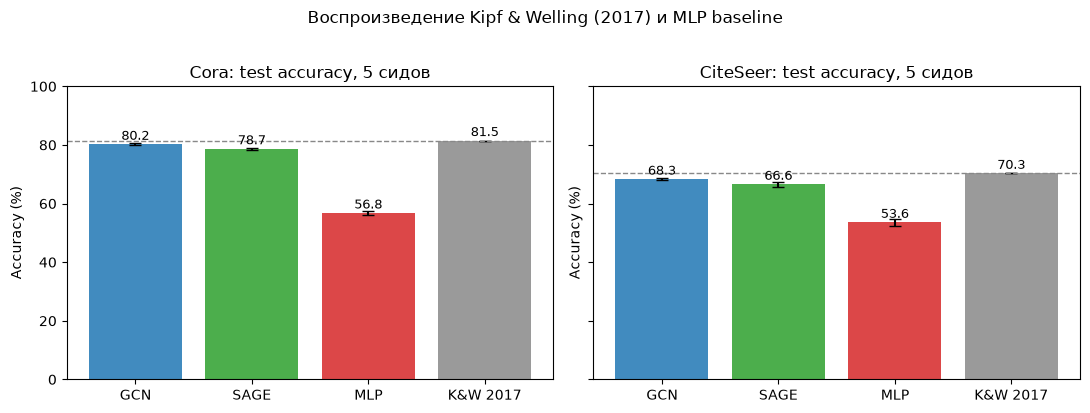

In [8]:
paper_scores = {"Cora": 81.5, "CiteSeer": 70.3}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (ds_name, model_results) in zip(axes, reproduction_results.items()):
    labels = ["GCN", "SAGE", "MLP", "K&W 2017"]
    means, stds = [], []
    for m in ["gcn", "sage", "mlp"]:
        means.append(np.mean(model_results[m]) * 100)
        stds.append(np.std(model_results[m]) * 100)
    means.append(paper_scores[ds_name])
    stds.append(0.0)
    colors = ["#1f77b4", "#2ca02c", "#d62728", "#888888"]
    bars = ax.bar(labels, means, yerr=stds, capsize=4, color=colors, alpha=0.85)
    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                f"{mean:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{ds_name}: test accuracy, 5 сидов")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 100)
    ax.axhline(paper_scores[ds_name], color="#888888", linestyle="--", linewidth=1)
fig.suptitle("Воспроизведение Kipf & Welling (2017) и MLP baseline", y=1.02)
plt.tight_layout()
plt.show()

### Вывод по части 2

(заполняется после прогона — см. ячейку ниже)

In [9]:
for ds_name in ["Cora", "CiteSeer"]:
    gcn = np.mean(reproduction_results[ds_name]["gcn"]) * 100
    mlp = np.mean(reproduction_results[ds_name]["mlp"]) * 100
    paper = paper_scores[ds_name]
    gap_paper = gcn - paper
    gap_mlp = gcn - mlp
    print(f"{ds_name}: GCN {gcn:.1f} | статья {paper:.1f} (отклонение {gap_paper:+.1f} п.п., "
          f"{'в пределах ±2 п.п. ✓' if abs(gap_paper) <= 2 else 'вне диапазона ✗'}) | "
          f"MLP {mlp:.1f} (граф даёт +{gap_mlp:.1f} п.п.)")

Cora: GCN 80.2 | статья 81.5 (отклонение -1.3 п.п., в пределах ±2 п.п. ✓) | MLP 56.8 (граф даёт +23.5 п.п.)
CiteSeer: GCN 68.3 | статья 70.3 (отклонение -2.0 п.п., в пределах ±2 п.п. ✓) | MLP 53.6 (граф даёт +14.7 п.п.)


## Часть 3 — что ломается при увеличении глубины

Обучаем GCN с 2, 4, 8 и 16 слоями (та же схема обучения, ранний останов по валидации). Для каждой глубины дополнительно измеряем **среднее попарное косинусное сходство** выходов предпоследнего (последнего скрытого) слоя на тестовых вершинах — это численная диагностика over-smoothing.

In [10]:
def hidden_representation(model: GCNNet, data: Data) -> Tensor:
    """Пропускает данные через все слои, кроме последнего, возвращает скрытое представление."""
    model.eval()
    x = data.x
    with torch.no_grad():
        for conv in model.convs[:-1]:
            x = F.relu(conv(x, data.edge_index))
    return x


depth_results: Dict[str, Dict[int, Dict[str, List[float]]]] = {}

for ds_name, data in datasets.items():
    print(f"\n=== {ds_name} ===")
    depth_results[ds_name] = {}
    for n_layers in N_LAYERS_DEPTH:
        accs, sims, norms, zeros = [], [], [], []
        for seed in SEEDS:
            set_seed(seed)
            model = build_model("gcn", data.num_features, num_classes_map[ds_name], n_layers=n_layers)
            model, _ = train_model(
                model, data, data.train_mask, eval_mask=data.val_mask, early_stop_patience=30
            )
            accs.append(accuracy_on(model, data, data.test_mask))
            hidden = hidden_representation(model, data)
            sims.append(mean_cosine_similarity(hidden, sample_size=512, seed=seed))
            norms.append(hidden.norm(dim=1).mean().item())
            zeros.append((hidden.norm(dim=1) < 1e-8).float().mean().item())
        depth_results[ds_name][n_layers] = {"acc": accs, "sim": sims, "norm": norms, "zeros": zeros}
        print(f"  глубина {n_layers:>2}: acc {summarize(accs)} | cos-sim {np.mean(sims):.3f} +/- {np.std(sims):.3f} | norm {np.mean(norms):.4f} | zero {np.mean(zeros):.1%}")


=== Cora ===
  глубина  2: acc 80.2 ± 0.4 | cos-sim 0.733 +/- 0.007 | norm 6.1726 | zero 0.0%
  глубина  4: acc 77.2 ± 1.0 | cos-sim 0.739 +/- 0.024 | norm 13.6405 | zero 0.0%
  глубина  8: acc 23.8 ± 6.6 | cos-sim 0.900 +/- 0.110 | norm 1.2531 | zero 0.0%
  глубина 16: acc 16.4 ± 0.5 | cos-sim 0.929 +/- 0.033 | norm 1.2889 | zero 0.0%

=== CiteSeer ===
  глубина  2: acc 68.3 ± 0.3 | cos-sim 0.803 +/- 0.010 | norm 6.6709 | zero 0.0%
  глубина  4: acc 64.2 ± 4.3 | cos-sim 0.747 +/- 0.021 | norm 8.1567 | zero 0.0%
  глубина  8: acc 22.1 ± 3.6 | cos-sim 0.868 +/- 0.263 | norm 1.2530 | zero 7.8%
  глубина 16: acc 21.0 ± 1.6 | cos-sim 0.997 +/- 0.003 | norm 1.1323 | zero 0.0%


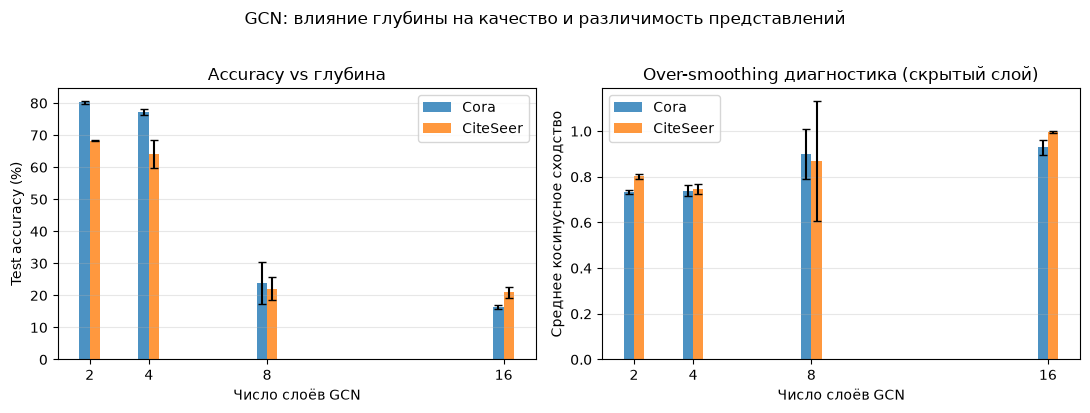

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x_layers = N_LAYERS_DEPTH
width = 0.35

for ax_idx, metric in enumerate(["acc", "sim"]):
    ax = axes[ax_idx]
    for i, ds_name in enumerate(["Cora", "CiteSeer"]):
        means = [np.mean(depth_results[ds_name][L][metric]) for L in x_layers]
        stds = [np.std(depth_results[ds_name][L][metric]) for L in x_layers]
        if metric == "acc":
            means = [value * 100 for value in means]
            stds = [value * 100 for value in stds]
        offset = (i - 0.5) * width
        ax.bar([x + offset for x in x_layers], means, width, yerr=stds, capsize=3,
               label=ds_name, alpha=0.8)
    ax.set_xticks(x_layers)
    ax.set_xlabel("Число слоёв GCN")
    if metric == "acc":
        ax.set_ylabel("Test accuracy (%)")
        ax.set_title("Accuracy vs глубина")
    else:
        ax.set_ylabel("Среднее косинусное сходство")
        ax.set_title("Over-smoothing диагностика (скрытый слой)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("GCN: влияние глубины на качество и различимость представлений", y=1.02)
plt.tight_layout()
plt.show()

### Объяснение (заполняется после прогона)

(см. ячейку ниже — вывод формируется из реальных чисел)

In [12]:
for ds_name in ["Cora", "CiteSeer"]:
    print(f"\n{ds_name}:")
    for L in N_LAYERS_DEPTH:
        acc_mean = np.mean(depth_results[ds_name][L]["acc"]) * 100
        sim_mean = np.mean(depth_results[ds_name][L]["sim"])
        print(f"  {L:>2} слоёв: acc {acc_mean:.1f}% | cos-sim {sim_mean:.3f}")


Cora:
   2 слоёв: acc 80.2% | cos-sim 0.733
   4 слоёв: acc 77.2% | cos-sim 0.739
   8 слоёв: acc 23.8% | cos-sim 0.900
  16 слоёв: acc 16.4% | cos-sim 0.929

CiteSeer:
   2 слоёв: acc 68.3% | cos-sim 0.803
   4 слоёв: acc 64.2% | cos-sim 0.747
   8 слоёв: acc 22.1% | cos-sim 0.868
  16 слоёв: acc 21.0% | cos-sim 0.997


Косинусное сходство измерено на случайной выборке всех вершин. При 16 слоях точность обоих наборов падает, а сходство становится высоким: на CiteSeer оно почти равно единице. Средние нормы при этом ненулевые и нулевые векторы отсутствуют, что согласуется со схлопыванием направлений. При глубине 8 на CiteSeer встречаются нулевые представления; вместе с низкой точностью это также указывает на проблемы обучения. Одного косинусного сходства недостаточно для доказательства причины падения качества.


## Бонус A — inductive vs transductive на GraphSAGE

Протокол:
1. Выбираем 1000 вершин из `test_mask` — «новые» вершины.
2. **Обучающий подграф**: удаляем эти вершины и все их рёбра через `torch_geometric.utils.subgraph`.
3. **Inductive**: обучаем двухслойный SAGE на подграфе, затем без переобучения прогоняем по **полному** графу (новые вершины приходят со своими рёбрами) и считаем accuracy на новых.
4. **Transductive**: обучаем ту же модель на полном графе (все вершины и рёбра видны, метки только у train) и считаем accuracy на тех же новых вершинах.

> Ловушка из задания: обучение на полном графе со скрытыми метками — это transductive. В inductive-режиме при обучении нет ни самих новых вершин, ни их рёбер.

Ранний останов по валидации внутри обучающего подграфа (inductive) и на полном графе (transductive).

In [13]:
N_NEW = 1000

def make_train_subgraph(data: Data, new_nodes: Tensor) -> Tuple[Data, Tensor]:
    """Удаляет new_nodes и все их рёбра; возвращает (подграф, маппинг старых индексов)."""
    keep = ~new_nodes
    edge_index_sub, _ = subgraph(
        subset=keep,
        edge_index=data.edge_index,
        relabel_nodes=True,
        num_nodes=data.num_nodes,
    )
    x_sub = data.x[keep]
    y_sub = data.y[keep]
    data_sub = Data(x=x_sub, edge_index=edge_index_sub, y=y_sub).to(DEVICE)
    # маппинг: индекс в подграфе -> исходный индекс
    old_indices = torch.nonzero(keep).flatten()
    return data_sub, old_indices


def inductive_transductive_eval(
    data: Data,
    seeds: List[int],
    n_new: int = N_NEW,
) -> Dict[str, List[float]]:
    """Один полный прогон бонуса A; возвращает accuracy для inductive и transductive."""
    # Вершины нового теста — первые n_new из test_mask (детерминированно)
    test_indices = torch.nonzero(data.test_mask).flatten()
    new_node_ids = test_indices[:n_new]
    new_mask = torch.zeros(data.num_nodes, dtype=torch.bool, device=DEVICE)
    new_mask[new_node_ids] = True

    data_sub, old_indices = make_train_subgraph(data, new_mask)
    # маски подграфа по исходным индексам
    orig_index_of_sub = old_indices  # sub_idx -> orig_idx
    train_mask_sub = data.train_mask[orig_index_of_sub]
    val_mask_sub = data.val_mask[orig_index_of_sub]

    inductive_accs: List[float] = []
    transductive_accs: List[float] = []

    for seed in seeds:
        set_seed(seed)
        # ---- inductive: обучение на подграфе, инференс на полном графе ----
        model_ind = build_model("sage", data_sub.num_features, int(data.y.max().item()) + 1, n_layers=2)
        model_ind, _ = train_model(
            model_ind, data_sub, train_mask_sub,
            eval_mask=val_mask_sub, early_stop_patience=30,
        )
        acc_ind = accuracy_on(model_ind, data, new_mask)
        inductive_accs.append(acc_ind)

        # ---- transductive: обучение на полном графе ----
        set_seed(seed)  # та же инициализация для честного сравнения
        model_tr = build_model("sage", data.num_features, int(data.y.max().item()) + 1, n_layers=2)
        model_tr, _ = train_model(
            model_tr, data, data.train_mask,
            eval_mask=data.val_mask, early_stop_patience=30,
        )
        acc_tr = accuracy_on(model_tr, data, new_mask)
        transductive_accs.append(acc_tr)

    return {"inductive": inductive_accs, "transductive": transductive_accs}


bonus_a_results: Dict[str, Dict[str, List[float]]] = {}
for ds_name in ["Cora", "CiteSeer"]:
    print(f"\n=== {ds_name} ===")
    res = inductive_transductive_eval(datasets[ds_name], SEEDS)
    bonus_a_results[ds_name] = res
    for mode in ["inductive", "transductive"]:
        runs_str = ", ".join(f"{a * 100:.1f}" for a in res[mode])
        print(f"  {mode:>12}: {summarize(res[mode])}  (запуски: {runs_str})")


=== Cora ===
     inductive: 77.5 ± 0.6  (запуски: 76.9, 78.3, 77.7, 77.9, 76.8)
  transductive: 78.7 ± 0.4  (запуски: 78.1, 79.1, 79.0, 78.5, 78.8)

=== CiteSeer ===
     inductive: 67.4 ± 0.5  (запуски: 67.9, 66.5, 67.6, 67.7, 67.5)
  transductive: 66.6 ± 0.8  (запуски: 66.6, 66.7, 67.7, 66.7, 65.2)


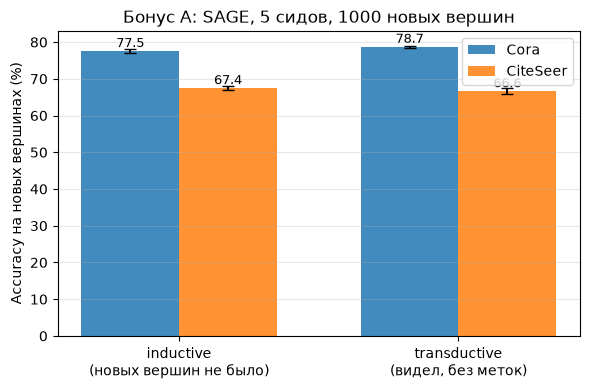

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
modes = ["inductive", "transductive"]
x_pos = np.arange(len(modes))
width = 0.35
for i, ds_name in enumerate(["Cora", "CiteSeer"]):
    means = [np.mean(bonus_a_results[ds_name][m]) * 100 for m in modes]
    stds = [np.std(bonus_a_results[ds_name][m]) * 100 for m in modes]
    offset = (i - 0.5) * width
    bars = ax.bar(x_pos + offset, means, width, yerr=stds, capsize=4, label=ds_name, alpha=0.85)
    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f"{mean:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x_pos)
ax.set_xticklabels(["inductive\n(новых вершин не было)", "transductive\n(видел, без меток)"])
ax.set_ylabel("Accuracy на новых вершинах (%)")
ax.set_title(f"Бонус A: SAGE, {len(SEEDS)} сидов, {N_NEW} новых вершин")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Результаты бонуса A

Inductive модель не видит новые вершины и их рёбра при обучении; transductive модель видит их признаки и связи, но не метки. Разница может зависеть от доступного соседства и изменений при валидации; улучшение не гарантировано.


In [15]:
for ds_name in ["Cora", "CiteSeer"]:
    print(f"\n{ds_name}")
    print("Режим | Новые вершины видны при обучении | Accuracy, mean ± std (%)")
    print(f"inductive | нет | {summarize(bonus_a_results[ds_name]['inductive'])}")
    print(f"transductive | да, без меток | {summarize(bonus_a_results[ds_name]['transductive'])}")
    gap = 100 * (np.mean(bonus_a_results[ds_name]["transductive"]) - np.mean(bonus_a_results[ds_name]["inductive"]))
    print(f"Разница transductive − inductive: {gap:+.1f} п.п.")



Cora
Режим | Новые вершины видны при обучении | Accuracy, mean ± std (%)
inductive | нет | 77.5 ± 0.6
transductive | да, без меток | 78.7 ± 0.4
Разница transductive − inductive: +1.2 п.п.

CiteSeer
Режим | Новые вершины видны при обучении | Accuracy, mean ± std (%)
inductive | нет | 67.4 ± 0.5
transductive | да, без меток | 66.6 ± 0.8
Разница transductive − inductive: -0.9 п.п.


## Бонус B — сколько разметки нужно графу

Для эксперимента фиксируем непересекающиеся случайные 20% тестовых и 10% валидационных вершин; остальные 70% образуют пул обучения. Доли 1%, 5%, 20%, 60% относятся ко **всем вершинам** графа. Для каждого сида выбираем вложенные подмножества пула с представителями каждого класса. Граф виден при обучении; тестовые и валидационные метки не используются для обучения.


In [16]:
def make_label_mask(
    data: Data,
    fraction: float,
    generator: torch.Generator,
    n_classes: int,
) -> Tensor:
    """Стратифицированная маска размеченных вершин из train_pool.

    Сначала по одной вершине на класс, затем добирает случайные вершины
    до нужной доли. Возвращает bool-маску длины num_nodes.
    """
    train_pool = torch.nonzero(data.train_mask).flatten()
    n_total = train_pool.numel()
    n_label = max(int(round(data.num_nodes * fraction)), n_classes)
    n_label = min(n_label, n_total)

    perm = train_pool[torch.randperm(n_total, generator=generator, device=DEVICE)]
    # стратификация: первая проходка — гарантируем классы
    chosen: List[int] = []
    seen_classes = set()
    for idx in perm.tolist():
        cls = data.y[idx].item()
        if cls not in seen_classes:
            seen_classes.add(cls)
            chosen.append(idx)
        if len(chosen) == n_classes:
            break
    # добор случайных из оставшихся
    remaining = [i for i in perm.tolist() if i not in set(chosen)]
    need = n_label - len(chosen)
    if need > 0:
        chosen.extend(remaining[:need])

    mask = torch.zeros(data.num_nodes, dtype=torch.bool, device=DEVICE)
    mask[torch.tensor(chosen, device=DEVICE)] = True
    return mask


def label_fraction_experiment(
    data: Data,
    fractions: List[float],
    seeds: List[int],
) -> Dict[str, Dict[float, List[float]]]:
    """GCN vs MLP при разных долях разметки; возвращает acc по сидам для каждой доли."""
    results: Dict[str, Dict[float, List[float]]] = {
        "gcn": {f: [] for f in fractions},
        "mlp": {f: [] for f in fractions},
    }
    val_mask = data.val_mask  # фиксированная валидация — не входит в обучение

    for fraction in fractions:
        for seed in seeds:
            gen = torch.Generator(device=DEVICE).manual_seed(seed)
            label_mask = make_label_mask(data, fraction, gen, int(data.y.max().item()) + 1)
            for model_type in ["gcn", "mlp"]:
                set_seed(seed)
                model = build_model(model_type, data.num_features, int(data.y.max().item()) + 1, n_layers=2)
                model, _ = train_model(
                    model, data, label_mask,
                    eval_mask=val_mask, early_stop_patience=30,
                )
                acc = accuracy_on(model, data, data.test_mask)
                results[model_type][fraction].append(acc)
    return results


bonus_b_results: Dict[str, Dict[str, Dict[float, List[float]]]] = {}
for ds_name in ["Cora", "CiteSeer"]:
    print(f"\n=== {ds_name} ===")
    data = datasets[ds_name].clone()
    gen = torch.Generator(device=DEVICE).manual_seed(2026)
    order = torch.randperm(data.num_nodes, generator=gen, device=DEVICE)
    n_test = int(0.20 * data.num_nodes)
    n_val = int(0.10 * data.num_nodes)
    data.test_mask = torch.zeros(data.num_nodes, dtype=torch.bool, device=DEVICE)
    data.val_mask = torch.zeros_like(data.test_mask)
    data.train_mask = torch.zeros_like(data.test_mask)
    data.test_mask[order[:n_test]] = True
    data.val_mask[order[n_test:n_test+n_val]] = True
    data.train_mask[order[n_test+n_val:]] = True
    res = label_fraction_experiment(data, LABEL_FRACIONS, SEEDS)
    bonus_b_results[ds_name] = res
    for fraction in LABEL_FRACIONS:
        gcn_m = np.mean(res["gcn"][fraction]) * 100
        mlp_m = np.mean(res["mlp"][fraction]) * 100
        print(f"  {fraction:>4.0%}: GCN {gcn_m:.1f}% | MLP {mlp_m:.1f}% | разница {gcn_m - mlp_m:+.1f} п.п.")


=== Cora ===
    1%: GCN 60.1% | MLP 34.9% | разница +25.2 п.п.
    5%: GCN 80.1% | MLP 60.2% | разница +20.0 п.п.
   20%: GCN 86.0% | MLP 71.0% | разница +15.0 п.п.
   60%: GCN 89.3% | MLP 77.7% | разница +11.6 п.п.

=== CiteSeer ===
    1%: GCN 51.3% | MLP 39.7% | разница +11.6 п.п.
    5%: GCN 67.3% | MLP 57.6% | разница +9.8 п.п.
   20%: GCN 71.6% | MLP 68.8% | разница +2.9 п.п.
   60%: GCN 75.1% | MLP 72.4% | разница +2.7 п.п.


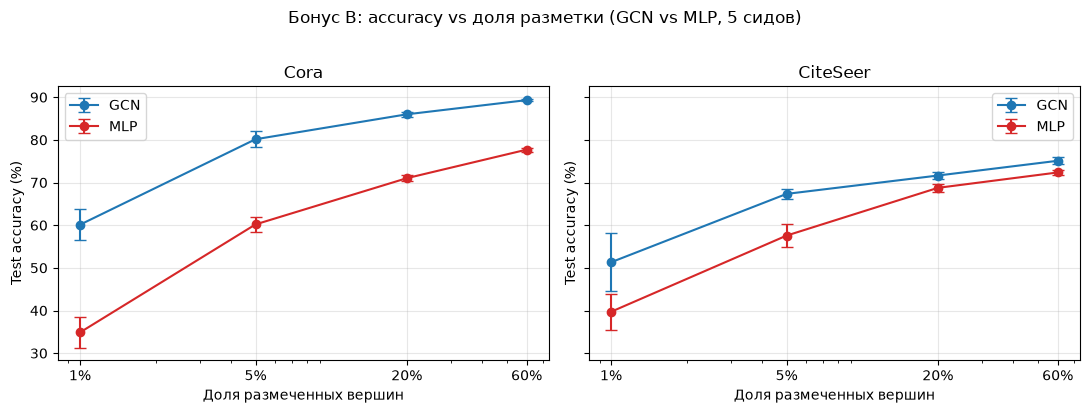

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds_name in zip(axes, ["Cora", "CiteSeer"]):
    for model_type, color, label in [("gcn", "#1f77b4", "GCN"), ("mlp", "#d62728", "MLP")]:
        means = [np.mean(bonus_b_results[ds_name][model_type][f]) * 100 for f in LABEL_FRACIONS]
        stds = [np.std(bonus_b_results[ds_name][model_type][f]) * 100 for f in LABEL_FRACIONS]
        ax.errorbar(
            [f * 100 for f in LABEL_FRACIONS], means, yerr=stds,
            marker="o", capsize=4, color=color, label=label, linewidth=1.5,
        )
    ax.set_xscale("log")
    ax.set_xticks([f * 100 for f in LABEL_FRACIONS])
    ax.set_xticklabels([f"{f:.0%}" for f in LABEL_FRACIONS])
    ax.set_xlabel("Доля размеченных вершин")
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title(ds_name)
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("Бонус B: accuracy vs доля разметки (GCN vs MLP, 5 сидов)", y=1.02)
plt.tight_layout()
plt.show()

### Вывод по бонусу B

В этом эксперименте преимущество GCN не исчезло даже при 60% разметки: на Cora оно составило 11,6 п.п., на CiteSeer — 2,7 п.п. С увеличением числа меток MLP лучше учится по признакам и разрыв сокращается; связи между похожими вершинами могут давать GCN дополнительную информацию. Это наблюдение относится к использованным разбиениям и гиперпараметрам.


In [18]:
for ds_name in ["Cora", "CiteSeer"]:
    print(f"\n{ds_name}:")
    for f in LABEL_FRACIONS:
        gcn_m = np.mean(bonus_b_results[ds_name]["gcn"][f]) * 100
        mlp_m = np.mean(bonus_b_results[ds_name]["mlp"][f]) * 100
        print(f"  {f:>4.0%}: GCN {gcn_m:.1f}% | MLP {mlp_m:.1f}% | Δ = {gcn_m - mlp_m:+.1f} п.п.")


Cora:
    1%: GCN 60.1% | MLP 34.9% | Δ = +25.2 п.п.
    5%: GCN 80.1% | MLP 60.2% | Δ = +20.0 п.п.
   20%: GCN 86.0% | MLP 71.0% | Δ = +15.0 п.п.
   60%: GCN 89.3% | MLP 77.7% | Δ = +11.6 п.п.

CiteSeer:
    1%: GCN 51.3% | MLP 39.7% | Δ = +11.6 п.п.
    5%: GCN 67.3% | MLP 57.6% | Δ = +9.8 п.п.
   20%: GCN 71.6% | MLP 68.8% | Δ = +2.9 п.п.
   60%: GCN 75.1% | MLP 72.4% | Δ = +2.7 п.п.


## Итог

GCN воспроизводит значения статьи в пределах ±2 п.п. для обоих наборов; CiteSeer расположен у границы допуска. Все численные оценки приведены со стандартным отклонением по пяти сидам. Эпоха выбиралась по validation, тест использовался для итоговой оценки.
